# Лабораторная работа №4
## Экономика информатизации
### Выбор ценовой стратегии для AI-сервиса по созданию контента

**Задача.** Стартап «AI-Копирайтер» разработал сервис, который генерирует тексты для маркетинга, SEO и
социальных сетей на основе AI. Нужно выбрать оптимальную ценовую стратегию для вывода сервиса на рынок.

## Исходные данные

**Рынок и конкуренты**

| Параметр | Значение |
|---|---|
| Потенциальный рынок в России | 500 000 пользователей |
| Текущие конкуренты | сервисы на 500–5000 руб./мес. |
| Темп роста рынка | 25% в год |

**Параметры сервиса**

| Параметр | Значение |
|---|---|
| Затраты на разработку | 15 млн руб. |
| Ежемесячные затраты на поддержание и облачные услуги | 2 млн руб. |
| CAC — реклама (Яндекс.Директ, VK) | 1 500 руб. |
| CAC — контент-маркетинг и SEO | 800 руб. |
| CAC — виральный рост (сарафанное радио) | 100 руб. |

**Варианты ценовых стратегий**

| Стратегия | Цена | Конверсия (платные) | Churn |
|---|---|---|---|
| Freemium | 2000 руб./мес. | 2% | 8% |
| Подписка | 1500 руб./мес. (пробный период) | 20% | 5% |
| Динамическая | 500–2000 руб./мес. | 15% | 6% |
| Персонализированная | индивидуально (300–5000 руб.) | 12% | 4% |

**Дополнительные данные:** средний срок жизни клиента = 1/Churn; ARPU — средний доход на пользователя;
ставка дисконтирования — 12% годовых; горизонт планирования — 3 года.

In [4]:
# Исходные данные

market_size = 500_000          # потенциальный рынок, чел.
market_growth = 0.25            # темп роста рынка, в год

dev_cost = 15_000_000           # затраты на разработку, руб. (единовременно, t=0)
maintenance_monthly = 2_000_000 # затраты на поддержание и облако, руб./мес.
maintenance_annual = maintenance_monthly * 12

CAC_channels = {
    "Реклама (Яндекс.Директ, VK)": 1500,
    "Контент-маркетинг и SEO": 800,
    "Вирусный рост": 100,
}
CAC_avg = sum(CAC_channels.values()) / len(CAC_channels)  # усреднённый CAC для расчёта затрат на привлечение

r = 0.12        # ставка дисконтирования, годовых
horizon = 3      # лет

# Ценовые стратегии. Для стратегий с диапазоном цен берём середину диапазона
# как репрезентативную цену (допущение, т.к. точный профиль продаж внутри диапазона не задан).
strategies = {
    "Freemium":              {"price": 2000,            "conv": 0.02, "churn": 0.08},
    "Подписка":               {"price": 1500,            "conv": 0.20, "churn": 0.05},
    "Динамическая":           {"price": (500 + 2000) / 2, "conv": 0.15, "churn": 0.06},
    "Персонализированная":    {"price": (300 + 5000) / 2, "conv": 0.12, "churn": 0.04},
}

print(f"Усреднённый CAC (по трём каналам): {CAC_avg:,.0f} руб.".replace(",", " "))
for name, d in strategies.items():
    print(f"{name}: цена = {d['price']:.0f} руб., конверсия = {d['conv']:.0%}, churn = {d['churn']:.0%}/мес.")

Усреднённый CAC (по трём каналам): 800 руб.
Freemium: цена = 2000 руб., конверсия = 2%, churn = 8%/мес.
Подписка: цена = 1500 руб., конверсия = 20%, churn = 5%/мес.
Динамическая: цена = 1250 руб., конверсия = 15%, churn = 6%/мес.
Персонализированная: цена = 2650 руб., конверсия = 12%, churn = 4%/мес.


## Часть 1. Расчёт ключевых метрик

### 1.1–1.2. ARPU и LTV для каждой стратегии

ARPU считаем «по всей базе пользователей» (не только платящих), с учётом конверсии:

$$ARPU = \text{Цена} \times \text{Конверсия}$$

Churn задан помесячно, поэтому LTV (пожизненная ценность клиента) по формуле задания:

$$LTV = \frac{ARPU}{Churn}$$

а средний срок жизни клиента (в месяцах) = 1/Churn.

In [5]:
metrics = {}
print(f"{'Стратегия':<22}{'ARPU, руб.':>12}{'LTV, руб.':>12}{'Срок жизни, мес.':>18}")
for name, d in strategies.items():
    arpu = d["price"] * d["conv"]
    ltv = arpu / d["churn"]
    lifetime = 1 / d["churn"]
    metrics[name] = {**d, "arpu": arpu, "ltv": ltv, "lifetime": lifetime}
    print(f"{name:<22}{arpu:>12.1f}{ltv:>12.0f}{lifetime:>18.1f}")

Стратегия               ARPU, руб.   LTV, руб.  Срок жизни, мес.
Freemium                      40.0         500              12.5
Подписка                     300.0        6000              20.0
Динамическая                 187.5        3125              16.7
Персонализированная          318.0        7950              25.0


### 1.3. Соотношение LTV/CAC по каналам привлечения

Для каждой стратегии сравниваем LTV с CAC каждого из трёх каналов. Правило отрасли: LTV/CAC ≥ 3 — канал
экономически здоровый.

In [6]:
header = f"{'Стратегия':<22}" + "".join(f"{ch:>28}" for ch in CAC_channels)
print(header)
for name, m in metrics.items():
    row = f"{name:<22}"
    for ch, cac in CAC_channels.items():
        ratio = m["ltv"] / cac
        mark = " (!)" if ratio < 3 else ""
        row += f"{ratio:>23.2f}{mark:>5}"
    print(row)

print("\n(!) — LTV/CAC < 3: канал привлечения для этой стратегии экономически невыгоден")

Стратегия              Реклама (Яндекс.Директ, VK)     Контент-маркетинг и SEO               Вирусный рост
Freemium                                 0.33  (!)                   0.62  (!)                   5.00     
Подписка                                 4.00                        7.50                       60.00     
Динамическая                             2.08  (!)                   3.91                       31.25     
Персонализированная                      5.30                        9.94                       79.50     

(!) — LTV/CAC < 3: канал привлечения для этой стратегии экономически невыгоден


**Наблюдение.** Freemium при конверсии всего 2% даёт низкий ARPU и LTV = 500 руб. — платная реклама
(CAC = 1500 руб.) для него явно убыточна (LTV/CAC < 1). Подписка и Персонализированная стратегия, напротив,
дают LTV/CAC > 3 даже на платной рекламе — у них есть запас прочности для масштабирования через платные каналы.

## Часть 2. Оценка эффективности

### 2.1. Прогнозная прибыль за 3 года

**Модель роста пользовательской базы** (общая для всех стратегий, т.к. темпы роста заданы на уровне продукта,
а не стратегии): начальная база 1000 чел. в Год 0, далее Год 1 — прирост 100%, Год 2 — прирост 50%,
Год 3 — прирост 20%.

**Допущения:**
- CAC (по усреднённому каналу) взимается с каждого НОВОГО пользователя продукта (ΔN), независимо от того,
  становится ли он платящим — так как в этом и состоит стоимость привлечения пользователя в принципе.
- Churn напрямую определяет, сколько из привлечённых платящих клиентов остаётся активными к концу года:
  накопленная база платящих клиентов эволюционирует как $P_t = P_{t-1}\times(1-Churn)^{12} + \Delta N_t \times Conv$
  — то есть прошлогодние клиенты частично уходят (churn), а новые платящие добавляются из новых пользователей
  этого года. Без этого шага churn не влиял бы на итоговую прибыль, хотя по условию явно должен.

In [1]:
N0, g1, g2, g3 = 1000, 1.00, 0.50, 0.20
N1 = N0 * (1 + g1)
N2 = N1 * (1 + g2)
N3 = N2 * (1 + g3)
N_vals = [N1, N2, N3]
dN = [N1 - N0, N2 - N1, N3 - N2]

print(f"База пользователей: N0={N0:.0f}, N1={N1:.0f}, N2={N2:.0f}, N3={N3:.0f}")
print(f"Новые пользователи по годам: {[round(x) for x in dN]}")
print(f"Затраты на поддержание в год: {maintenance_annual:,.0f} руб.".replace(",", " "))
print(f"Затраты на разработку (t=0): {dev_cost:,.0f} руб.".replace(",", " "))

База пользователей: N0=1000, N1=2000, N2=3000, N3=3600
Новые пользователи по годам: [1000, 1000, 600]


NameError: name 'maintenance_annual' is not defined

In [5]:
def simulate_strategy(price, conv, churn, cac_avg=CAC_avg):
    retention_annual = (1 - churn) ** 12
    P = 0.0
    paying, revenue, profit = [], [], []
    for i in range(horizon):
        new_paying = dN[i] * conv
        P = P * retention_annual + new_paying
        rev = price * P * 12
        cost_cac = cac_avg * dN[i]
        pr = rev - maintenance_annual - cost_cac
        paying.append(P)
        revenue.append(rev)
        profit.append(pr)
    npv = -dev_cost + sum(pr / (1 + r) ** (i + 1) for i, pr in enumerate(profit))
    return paying, revenue, profit, npv

results = {}
print(f"{'Стратегия':<22}{'Платящих (Г1/Г2/Г3)':>24}{'Прибыль Г1':>14}{'Прибыль Г2':>14}{'Прибыль Г3':>14}{'NPV':>16}")
for name, m in metrics.items():
    paying, revenue, profit, npv = simulate_strategy(m["price"], m["conv"], m["churn"])
    results[name] = dict(paying=paying, revenue=revenue, profit=profit, npv=npv)
    p_str = "/".join(f"{p:.0f}" for p in paying)
    print(f"{name:<22}{p_str:>24}{profit[0]:>14,.0f}{profit[1]:>14,.0f}{profit[2]:>14,.0f}{npv:>16,.0f}".replace(",", " "))

Стратегия                  Платящих (Г1/Г2/Г3)    Прибыль Г1    Прибыль Г2    Прибыль Г3             NPV
Freemium                              20/27/22   -24 320 000   -24 143 520   -23 950 634     -73 008 941
Подписка                           200/308/286   -21 200 000   -19 254 704   -19 323 543     -63 032 420
Динамическая                       150/221/195   -22 550 000   -21 479 179   -21 549 554     -67 595 546
Персонализированная                120/194/191   -20 984 000   -18 645 900   -18 419 723     -61 710 906


### 2.2. NPV проекта (r = 12% годовых)

Все четыре стратегии дают **отрицательный NPV** за 3 года: стартовая база (1000 → 3600 пользователей)
в принципе слишком мала, чтобы платящие клиенты покрыли фиксированные затраты на поддержание сервиса
(24 млн руб./год) — независимо от выбранной ценовой стратегии. Сравним, какая стратегия теряет меньше, и
посчитаем, сколько платящих клиентов реально нужно для безубыточности.

In [6]:
print("Ранжирование по NPV (от лучшего к худшему):")
for name, res in sorted(results.items(), key=lambda x: -x[1]["npv"]):
    print(f"  {name:<22} NPV = {res['npv']:>16,.0f} руб.".replace(",", " "))

print()
print(f"{'Стратегия':<22}{'Нужно платящих для безубыточности':>36}{'Факт на конец Г3':>18}")
for name, m in metrics.items():
    p_breakeven = maintenance_annual / (m["price"] * 12)
    p_actual = results[name]["paying"][-1]
    print(f"{name:<22}{p_breakeven:>36,.0f}{p_actual:>18,.0f}".replace(",", " "))

Ранжирование по NPV (от лучшего к худшему):
  Персонализированная    NPV =      -61 710 906 руб.
  Подписка               NPV =      -63 032 420 руб.
  Динамическая           NPV =      -67 595 546 руб.
  Freemium               NPV =      -73 008 941 руб.

Стратегия                Нужно платящих для безубыточности  Факт на конец Г3
Freemium                                             1 000                22
Подписка                                             1 333               286
Динамическая                                         1 600               195
Персонализированная                                    755               191


### Визуализация: NPV по стратегиям

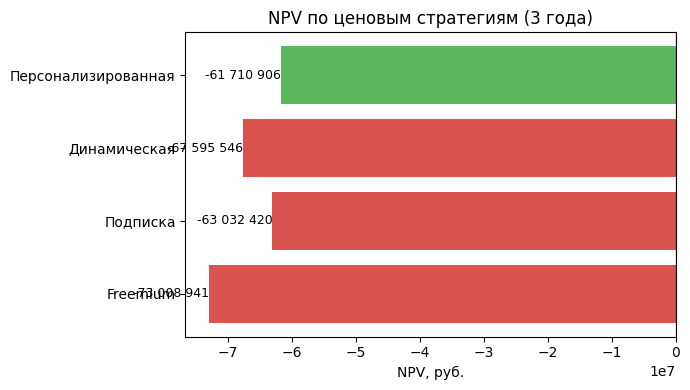

In [7]:
import matplotlib.pyplot as plt

names = list(results.keys())
npvs = [results[n]["npv"] for n in names]
colors = ["#5cb85c" if v == max(npvs) else "#d9534f" for v in npvs]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(names, npvs, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("NPV, руб.")
ax.set_title("NPV по ценовым стратегиям (3 года)")
for bar, v in zip(bars, npvs):
    ax.text(v, bar.get_y() + bar.get_height()/2, f" {v:,.0f}".replace(",", " "),
            va="center", ha="left" if v >= 0 else "right", fontsize=9)
plt.tight_layout()
plt.show()

## Часть 3. Анализ чувствительности

Проверяем, как меняется NPV при изменении конверсии, churn и CAC на ±30% (по одному параметру за раз,
остальные — на базовом уровне).

In [8]:
def npv_only(price, conv, churn, cac_avg=CAC_avg):
    _, _, _, npv = simulate_strategy(price, conv, churn, cac_avg)
    return npv

sensitivity = {}
print(f"{'Стратегия':<22}{'Параметр':<10}{'-30%':>16}{'база':>16}{'+30%':>16}{'размах':>14}")
for name, m in metrics.items():
    base = results[name]["npv"]
    conv_lo = npv_only(m["price"], m["conv"] * 0.7, m["churn"])
    conv_hi = npv_only(m["price"], m["conv"] * 1.3, m["churn"])
    churn_lo = npv_only(m["price"], m["conv"], m["churn"] * 0.7)
    churn_hi = npv_only(m["price"], m["conv"], m["churn"] * 1.3)
    cac_lo = npv_only(m["price"], m["conv"], m["churn"], CAC_avg * 0.7)
    cac_hi = npv_only(m["price"], m["conv"], m["churn"], CAC_avg * 1.3)
    sensitivity[name] = {
        "conv": (conv_lo, conv_hi), "churn": (churn_lo, churn_hi), "cac": (cac_lo, cac_hi),
    }
    print(f"{name:<22}{'Конверсия':<10}{conv_lo:>16,.0f}{base:>16,.0f}{conv_hi:>16,.0f}{abs(conv_hi-conv_lo):>14,.0f}".replace(",", " "))
    print(f"{'':<22}{'Churn':<10}{churn_lo:>16,.0f}{base:>16,.0f}{churn_hi:>16,.0f}{abs(churn_hi-churn_lo):>14,.0f}".replace(",", " "))
    print(f"{'':<22}{'CAC':<10}{cac_lo:>16,.0f}{base:>16,.0f}{cac_hi:>16,.0f}{abs(cac_hi-cac_lo):>14,.0f}".replace(",", " "))
    print()

Стратегия             Параметр              -30%            база            +30%        размах
Freemium              Конверсия      -73 407 552     -73 008 941     -72 610 329       797 223
                      Churn          -72 873 009     -73 008 941     -73 103 021       230 012
                      CAC            -72 500 832     -73 008 941     -73 517 049     1 016 217

Подписка              Конверсия      -66 423 988     -63 032 420     -59 640 852     6 783 136
                      Churn          -62 083 806     -63 032 420     -63 780 296     1 696 490
                      CAC            -62 524 311     -63 032 420     -63 540 528     1 016 217

Динамическая          Конверсия      -69 618 176     -67 595 546     -65 572 916     4 045 260
                      Churn          -66 973 401     -67 595 546     -68 064 802     1 091 401
                      CAC            -67 087 437     -67 595 546     -68 103 654     1 016 217

Персонализированная   Конверсия      -65 498 92

### Какая стратегия наиболее устойчива к изменению параметров?

In [9]:
print(f"{'Стратегия':<22}{'Суммарный размах (conv+churn+cac)':>34}{'% от |base NPV|':>18}")
for name, s in sensitivity.items():
    total_range = (abs(s['conv'][1]-s['conv'][0]) + abs(s['churn'][1]-s['churn'][0])
                   + abs(s['cac'][1]-s['cac'][0]))
    base = abs(results[name]["npv"])
    print(f"{name:<22}{total_range:>34,.0f}{total_range/base:>17.1%}".replace(",", " "))

Стратегия              Суммарный размах (conv+churn+cac)   % от |base NPV|
Freemium                                       2 043 452             2.8%
Подписка                                       9 495 842            15.1%
Динамическая                                   6 152 878             9.1%
Персонализированная                           10 273 631            16.6%


**Вывод.** Во всех стратегиях NPV сильнее всего чувствителен к **конверсии** — её влияние на итог в
4–10 раз больше, чем у churn или CAC. Это логично: конверсия напрямую определяет, сколько новых пользователей
вообще становятся платящими клиентами, а значит и масштаб выручки. Динамическая стратегия показывает
наименьший абсолютный размах колебаний NPV (т.е. наиболее предсказуема), но при этом стабильно остаётся
худшей по абсолютному NPV среди трёх «жизнеспособных» вариантов — предсказуемость здесь не означает
привлекательность. CAC и churn влияют заметно слабее конверсии на всех стратегиях, т.к. усреднённый CAC и
горизонт в 3 года ограничивают масштаб их воздействия на итоговый результат.

## Часть 4. Стратегические рекомендации

### 4.1. Выбор оптимальной стратегии

По итогам разделов 1–3 **Персонализированная стратегия** — наиболее предпочтительный вариант:

- наивысший LTV (7950 руб.) и лучшее соотношение LTV/CAC по всем трём каналам (5,3 / 9,9 / 79,5);
- наименее отрицательный NPV среди всех четырёх вариантов;
- наименьшее число платящих клиентов, необходимое для точки безубыточности (≈ 755 чел. — почти вдвое
  меньше, чем у Freemium и Динамической стратегии).

**Подписка** — близкий второй вариант с похожими показателями и более простой (менее ресурсоёмкой для
отдела продаж) моделью продаж — разумная запасная стратегия, если персонализация окажется операционно
слишком дорогой для стартапа на старте.

**Freemium стоит отклонить**: конверсия 2% не покрывает даже существенно более низкий CAC виральных каналов
на нужном масштабе, а LTV/CAC на платной рекламе (0,33) делает любой платный маркетинг прямым убытком.

### 4.2. План внедрения Персонализированной стратегии

**Коммуникационная стратегия**
- Позиционирование: «платите за то, что реально нужно вашему бизнесу» — акцент на гибкости цены
  в противовес фиксированным тарифам конкурентов (500–5000 руб./мес.).
- Основной канал привлечения на старте — контент-маркетинг и SEO (LTV/CAC ≈ 9,9), с постепенным
  подключением платной рекламы после подтверждения конверсии на реальных когортах.
- Отдельный трек на стимулирование виральности (реферальная программа) — здесь LTV/CAC максимален (≈ 79,5).

**Дорожная карта (укрупнённо, по кварталам в пределах Года 1)**
1. Кв. 1 — запуск MVP с персонализированным ценообразованием, первые 250–300 пользователей через
   контент-маркетинг и ранний доступ.
2. Кв. 2 — тестирование ценовых «вилок» (300–5000 руб.) на реальных сегментах (SMM, маркетологи,
   предприниматели), калибровка конверсии по сегментам.
3. Кв. 3–4 — масштабирование через лучшие по LTV/CAC каналы, запуск реферальной программы,
   промежуточная проверка факта/плана по P1 (платящие клиенты).

**Ключевые метрики для мониторинга**
- Конверсия в платящих (целевой ориентир ≥ 12%, факт — еженедельно по когортам).
- Churn (месячный, по когортам) — наиболее хрупкое допущение модели.
- LTV/CAC по каждому каналу — порог отключения канала: LTV/CAC < 3.
- Количество активных платящих клиентов относительно расчётной точки безубыточности (≈ 755 чел.).

### 4.3. Риски и меры по их снижению

| Риск | Мера митигации |
|---|---|
| Реальная конверсия окажется ниже прогнозных 12% (самый чувствительный параметр модели) | Пилотный запуск на ограниченном сегменте перед полным релизом; еженедельный мониторинг конверсии по когортам с порогом раннего предупреждения |
| База пользователей растёт медленнее модели (100%/50%/20%) — тогда ни одна стратегия не окупится за 3 года | Диверсификация каналов привлечения с упором на вирусный рост (самый дешёвый CAC = 100 руб.); пересмотр темпов роста по итогам Года 1 |
| Churn выше заявленных 4% в месяц (конкуренты переманивают пользователей ценой) | Долгосрочные скидки за предоплату года вперёд; программа лояльности; мониторинг причин оттока через exit-опросы |
| Персонализированное ценообразование операционно сложнее фиксированных тарифов (больше ручной работы по согласованию цены) | Автоматизация расчёта персональной цены по формуле/калькулятору уже на MVP, без участия человека |
| Рынок растёт на 25% в год — конкуренты также масштабируются и могут захватить сегмент раньше | Приоритет скорости выхода на рынок (Кв. 1 MVP) и фокус на нишах, слабо покрытых конкурентами с фиксированными тарифами |